## 기초데이터과학 (01분반)

## Lab 07. 데이터 시각화 실습 1

### 진행 방식

- **문제 단위**로 진행하며, 문제마다 제한시간이 있음
- 코드 셀의 주석을 참고하여 직접 코드를 작성할 것
- 실행 결과가 아래 **기대 출력**의 그래프와 같은 모양이면 정답
  - 색상이나 크기가 조금 달라도 괜찮음. 그래프의 종류, 축, 제목, 구분 기준이 같은지를 확인할 것
- 제한시간이 끝나면 다 같이 풀이 진행

### 실습 내용

| 문제 | 내용 | 작성할 것 |
|---|---|---|
| 1 | 선 그래프 그리고 꾸미기, 파일로 저장 | 코드 + 결과 해석 |
| 2 | 그래프 나란히 그리기와 y축 범위 | 코드 + 결과 해석 |
| 3 | 분포 보기 | 코드 |
| 4 | 그룹 간 비교 | 코드 + 결과 해석 |
| 5 | 질문에 맞는 그래프 고르기 | 답안 작성 |

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

---

## 문제 1. 선 그래프 그리고 꾸미기 (제한시간 15분)

- 어느 회사의 월별 매출과 비용 데이터
- 아래 셀을 먼저 실행할 것

In [2]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales  = [1200, 1350, 1450, 1380, 1500, 1680, 1820, 1950, 1780, 1650, 1900, 2100]
costs  = [ 800,  850,  900,  880,  920, 1000, 1050, 1100, 1020,  980, 1100, 1200]

#### 1-1. 월별 매출과 비용을 하나의 선 그래프로 그리시오.

- 매출은 실선과 원(`'o'`) 모양 점, 비용은 점선(`'--'`)과 네모(`'s'`) 모양 점으로 표현
- 범례에 각각 `Sales`, `Costs` 로 표시
- 제목은 `Monthly Sales and Costs`, x축 이름은 `Month`, y축 이름은 `Amount`
- 격자선 표시
- 그래프를 `monthly_sales.png` 파일로 저장 (해상도 150)

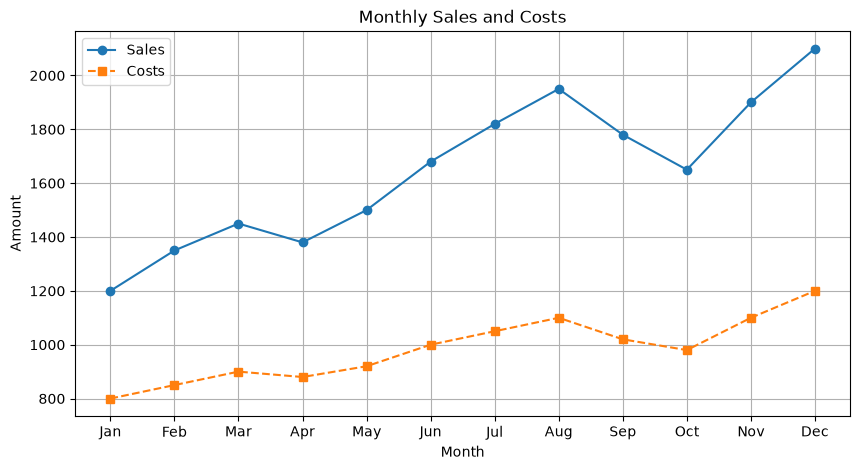

In [4]:
# 매출과 비용 선 그래프
plt.figure(figsize=(10, 5))
plt.plot(months, sales, marker='o', label='Sales')
plt.plot(months, costs, linestyle='--', marker='s', label='Costs')

# 제목, 축 이름, 범례, 격자선
plt.title('Monthly Sales and Costs')
plt.xlabel('Month')
plt.ylabel('Amount')
plt.legend()
plt.grid(True)

# 파일로 저장 후 출력
plt.savefig('monthly_sales.png', dpi=150)
plt.show()

**기대 출력**

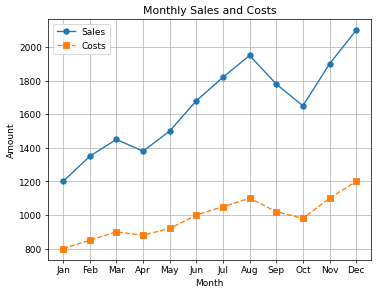


#### 1-2. 월별 이익률을 계산하고, 매출-비용 그래프와 위아래로 나누어 그리시오.

- 이익률(%) = (매출 - 비용) ÷ 매출 × 100
- 2행 1열로 나누고, 두 칸의 x축을 공유할 것
- 위 칸: 1-1 과 같은 매출-비용 선 그래프 (범례 포함), 제목은 `Sales and Costs`
- 아래 칸: 이익률 선 그래프 (점 모양은 `'o'`), 제목은 `Profit Margin (%)`
- 전체 크기는 가로 10, 세로 7
- 그래프를 그린 뒤 월별 이익률을 소수점 첫째 자리까지 출력할 것

> **힌트**
> - 리스트끼리는 빼기나 나누기 연산을 할 수 없음
> - 출력 결과에 월 이름이 함께 나오도록 만들어 볼 것

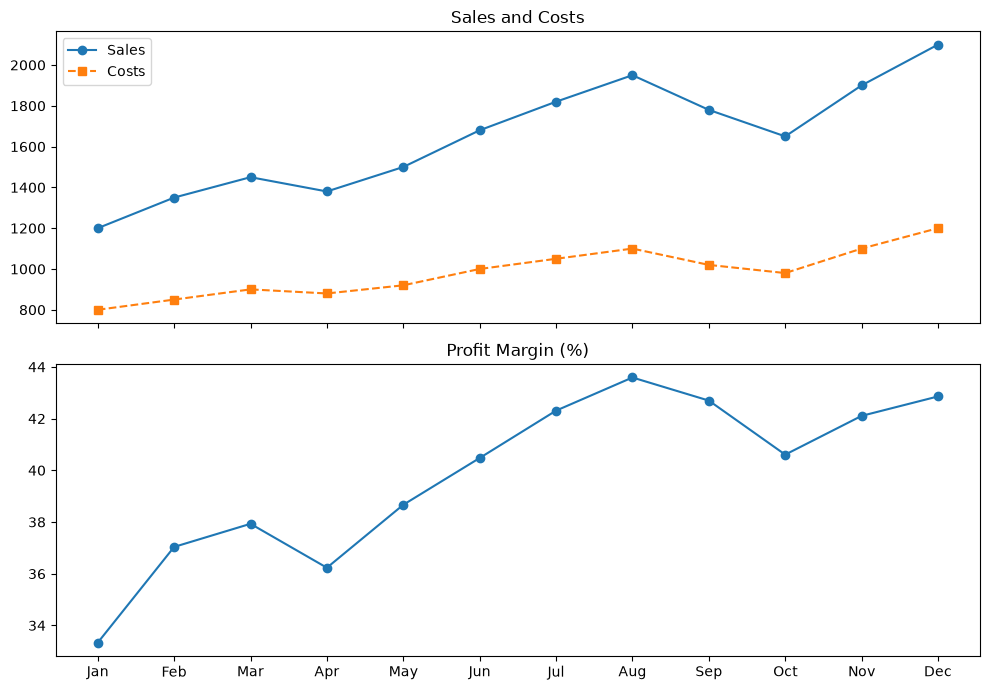

Jan    33.3
Feb    37.0
Mar    37.9
Apr    36.2
May    38.7
Jun    40.5
Jul    42.3
Aug    43.6
Sep    42.7
Oct    40.6
Nov    42.1
Dec    42.9
dtype: float64


In [5]:
# 이익률 계산
sales_by_month = pd.Series(sales, index=months)
costs_by_month = pd.Series(costs, index=months)
profit_margin = (sales_by_month - costs_by_month) / sales_by_month * 100

# 2행 1열 칸 만들기 (x축 공유)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# 위 칸 - 매출과 비용
axes[0].plot(months, sales, marker='o', label='Sales')
axes[0].plot(months, costs, linestyle='--', marker='s', label='Costs')
axes[0].set_title('Sales and Costs')
axes[0].legend()

# 아래 칸 - 이익률
axes[1].plot(months, profit_margin, marker='o')
axes[1].set_title('Profit Margin (%)')
fig.tight_layout()
plt.show()

# 이익률 출력
print(profit_margin.round(1))

**기대 출력**

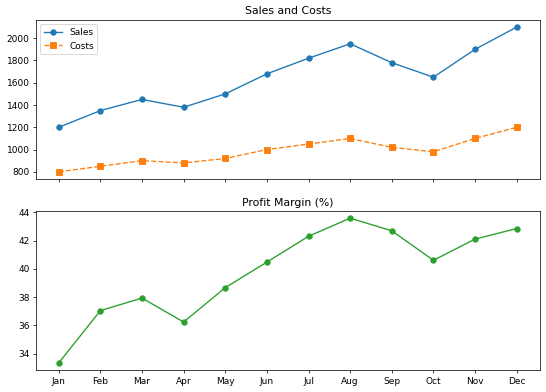

```
Jan    33.3
Feb    37.0
Mar    37.9
Apr    36.2
May    38.7
Jun    40.5
Jul    42.3
Aug    43.6
Sep    42.7
Oct    40.6
Nov    42.1
Dec    42.9
dtype: float64
```

#### 1-3. 1-1 과 1-2 의 결과를 보고 아래 물음에 답하시오.

- 매출이 가장 높은 달과 이익률이 가장 높은 달은 같은가?
- 다르다면 그 이유는 무엇이며, 이 차이가 무엇을 의미하는지 설명하시오.

---

##### 답안

- 매출이 가장 높은 달 / 이익률이 가장 높은 달: 매출 - 12월(2,100) / 이익률 - 8월(약 43.6%)
- 차이가 나는 이유와 의미: 이익률은 매출 자체가 아니라 매출에서 비용을 뺀 금액이 매출에서 차지하는 비율.이므로 8월은 비용이 매출의 약 56.4%인 반면 12월은 약 57.1%여서 12월 매출이 더 커도 8월 이익률이 더 높다. 매출 규모가 가장 큰 달이 수익성도 가장 높은 달은 아니다.

---

## 문제 2. 그래프 나란히 그리기와 y축 범위 (제한시간 15분)

- 두 제품의 월별 판매량 데이터
- 아래 셀을 먼저 실행할 것

In [7]:
month6    = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun']
product_a = [1020, 1080, 1150, 1100, 1210, 1280]
product_b = [ 110,  125,  140,  132,  158,  175]

#### 2-1. 두 제품의 판매량을 1행 2열로 나란히 그리시오.

- 왼쪽 칸에 제품 A, 오른쪽 칸에 제품 B 의 선 그래프를 그림 (점 모양은 `'o'`)
- 각 칸의 제목은 `Product A`, `Product B`
- 전체 크기는 가로 10, 세로 4

> **힌트**
> - 칸에 제목을 붙일 때는 `plt.title( )` 이 아니라 칸의 함수를 사용

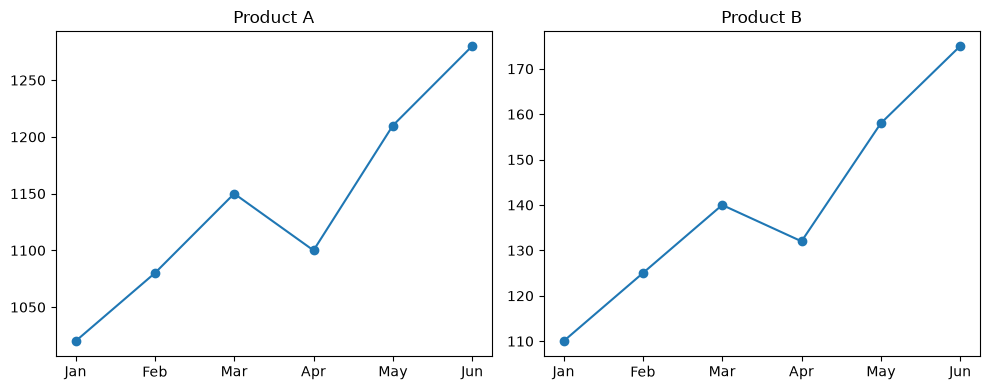

In [8]:
# 1행 2열 칸 만들기
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 왼쪽 칸 - 제품 A
axes[0].plot(month6, product_a, marker='o')
axes[0].set_title('Product A')

# 오른쪽 칸 - 제품 B
axes[1].plot(month6, product_b, marker='o')
axes[1].set_title('Product B')

fig.tight_layout()
plt.show()

**기대 출력**

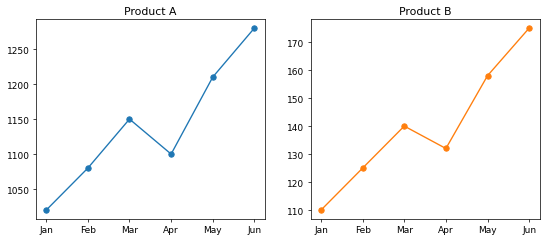


#### 2-2. 2-1과 같은 그래프를 두 칸의 y축 범위가 같도록 다시 그리시오.

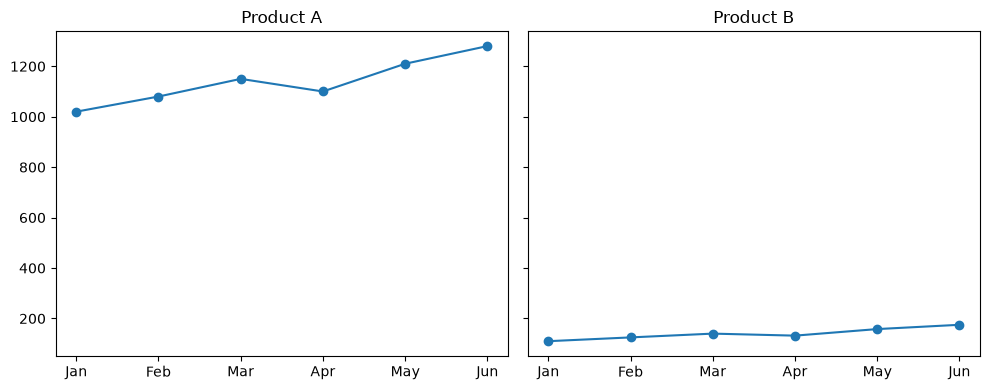

In [9]:
# y축 범위를 공유하는 1행 2열 칸 만들기
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# 왼쪽 칸 - 제품 A
axes[0].plot(month6, product_a, marker='o')
axes[0].set_title('Product A')

# 오른쪽 칸 - 제품 B
axes[1].plot(month6, product_b, marker='o')
axes[1].set_title('Product B')

fig.tight_layout()
plt.show()

**기대 출력**

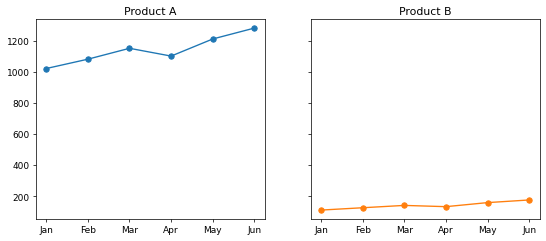


#### 2-3. 두 그래프를 비교하여 아래 물음에 답하시오.

- 2-1 그래프만 보았을 때 생길 수 있는 오해는 무엇인가?
- 반대로 2-2 그래프에서는 오히려 잘 보이지 않게 된 것은 무엇인가?

---

##### 답안

- 2-1 만 보았을 때의 오해: 두 그래프의 y축 범위가 각각 달라 제품 B의 판매량이 제품 A와 비슷한 수준이거나 두 제품의 절대적인 증가량이 비슷하다고 오해할 수 있다.
- 2-2 에서 잘 보이지 않게 된 것: 공통 y축에서 제품 B의 값과 변화 폭이 작게 눌려 제품 B가 1월 110개에서 6월 175개로 증가한 추세가 잘 드러나지 않는다.

#### 2-4. 2-3 에서 확인한 두 방법의 단점을 모두 피하여, 두 제품의 증가 추세를 하나의 그래프에서 공정하게 비교하시오.

- 두 제품을 한 그래프에 함께 그리고 (점 모양은 `'o'`), 범례에 `Product A`, `Product B` 로 표시
- 제목은 `Sales Index (Jan = 100)`

> **힌트**
> - 그래프의 설정이 아니라 **데이터를 바꾸어야** 해결됨
> - 각 제품의 판매량을 자기 자신의 1월 값과 비교한 값으로 바꾸어 볼 것

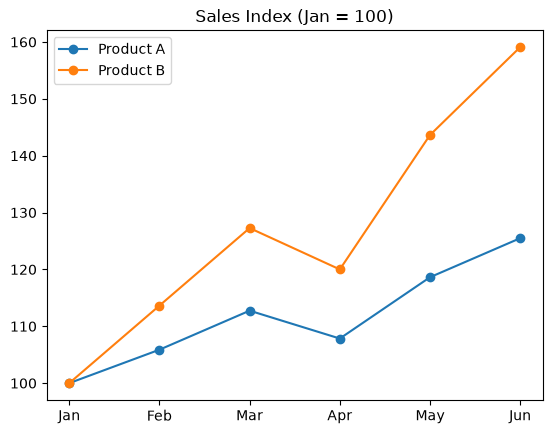

In [10]:
# 1월 값을 100 으로 하는 값으로 바꾸기
index_a = [value / product_a[0] * 100 for value in product_a]
index_b = [value / product_b[0] * 100 for value in product_b]

# 두 제품을 한 그래프에 그리기
plt.plot(month6, index_a, marker='o', label='Product A')
plt.plot(month6, index_b, marker='o', label='Product B')

# 제목, 범례
plt.title('Sales Index (Jan = 100)')
plt.legend()
plt.show()

**기대 출력**

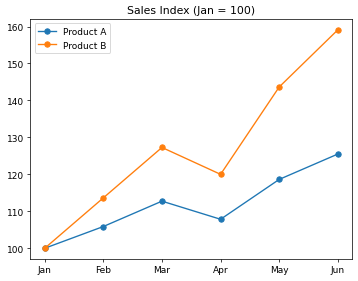


---

## 문제 3~4 데이터: 자동차 연비 데이터

- 5주차, 7주차에 사용한 mpg 데이터
- 아래 셀을 먼저 실행할 것

| 변수 | 의미 |
|---|---|
| `manufacturer` | 제조 회사 |
| `drv` | 구동 방식 (`f`: 전륜, `r`: 후륜, `4`: 사륜) |
| `cty`, `hwy` | 도시 연비, 고속도로 연비 |
| `category` | 자동차 종류 (compact, suv, pickup 등) |

In [11]:
mpg = pd.read_csv('mpg.csv')  # 저장소에 포함된 데이터로 실행

print(mpg.shape)
print(mpg[['manufacturer', 'drv', 'cty', 'hwy', 'category']].head())

(234, 11)
  manufacturer drv  cty  hwy category
0         audi   f   18   29  compact
1         audi   f   21   29  compact
2         audi   f   20   31  compact
3         audi   f   21   30  compact
4         audi   f   16   26  compact


---

## 문제 3. 분포 보기 (제한시간 10분)

#### 3-1. 고속도로 연비(`hwy`)의 분포를 히스토그램으로 그리시오.

- 구간 수는 15, 밀도 곡선을 함께 표시
- 제목은 `Distribution of Highway MPG`

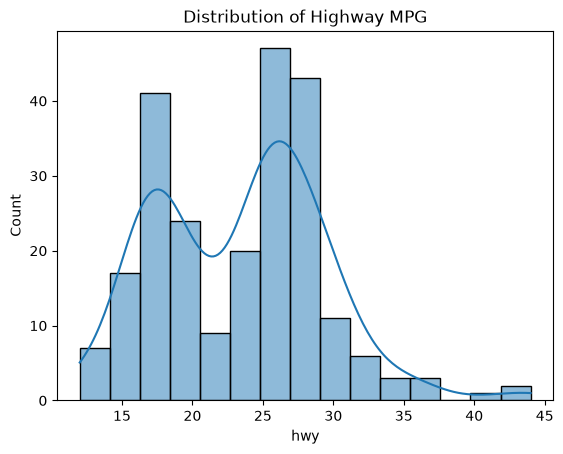

In [12]:
# 히스토그램 + 밀도 곡선
sns.histplot(data=mpg, x='hwy', bins=15, kde=True)

# 제목
plt.title('Distribution of Highway MPG')
plt.show()

**기대 출력**

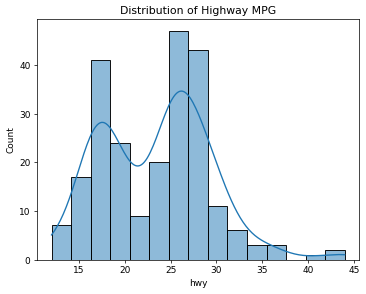


#### 3-2. 구동 방식(`drv`)별 고속도로 연비의 분포를 밀도 그래프로 겹쳐 그리시오.

- 구동 방식마다 색을 다르게 하고, 곡선 아래를 색으로 채울 것
- 제목은 `Highway MPG by Drive Type`

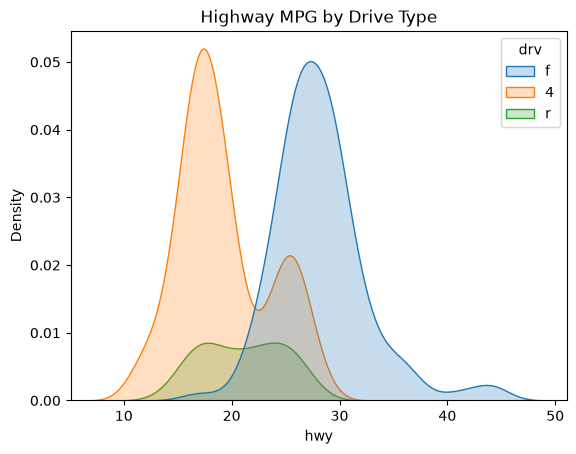

In [13]:
# 구동 방식별 밀도 그래프
sns.kdeplot(data=mpg, x='hwy', hue='drv', fill=True)

# 제목
plt.title('Highway MPG by Drive Type')
plt.show()

**기대 출력**

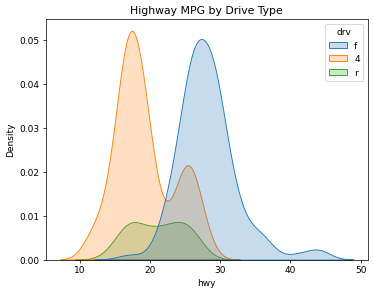


---

## 문제 4. 그룹 간 비교 (제한시간 12분)

#### 4-1. 구동 방식별 고속도로 연비를 상자 그림과 바이올린 그래프로 나란히 그리시오.

- 1행 2열, 전체 크기는 가로 12, 세로 4
- 왼쪽 칸은 상자 그림, 오른쪽 칸은 바이올린 그래프
- 각 칸의 제목은 `Box plot`, `Violin plot`

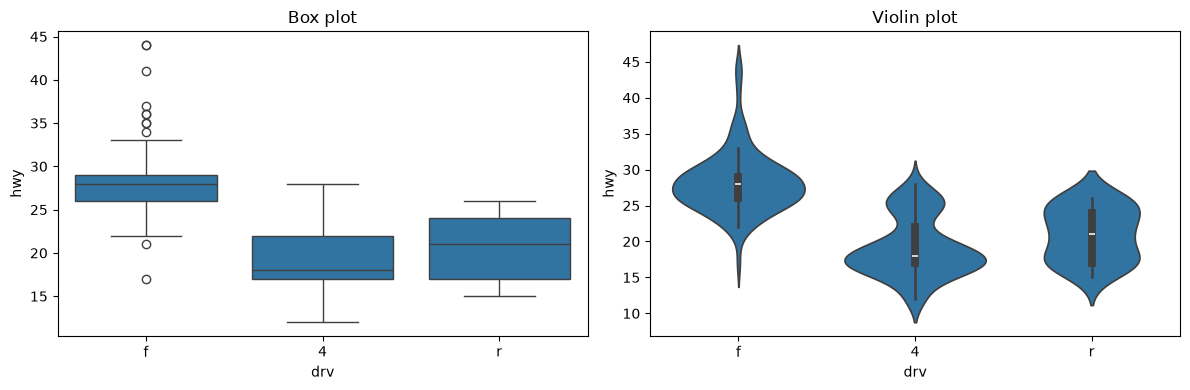

In [14]:
# 1행 2열 칸 만들기
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 왼쪽 칸 - 상자 그림
sns.boxplot(data=mpg, x='drv', y='hwy', ax=axes[0])
axes[0].set_title('Box plot')

# 오른쪽 칸 - 바이올린 그래프
sns.violinplot(data=mpg, x='drv', y='hwy', ax=axes[1])
axes[1].set_title('Violin plot')

fig.tight_layout()
plt.show()

**기대 출력**

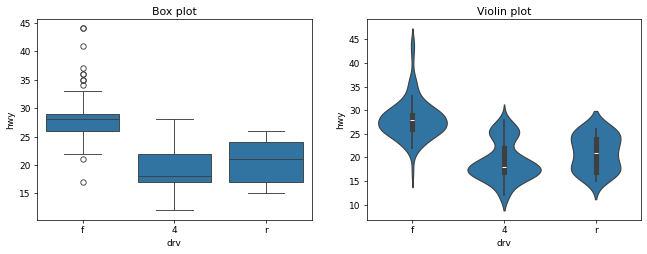


#### 4-2. 자동차 종류(`category`)별 차량 수를 막대 그래프로 그리시오.

- 구동 방식에 따라 색을 구분
- 제목은 `Number of Cars by Category`

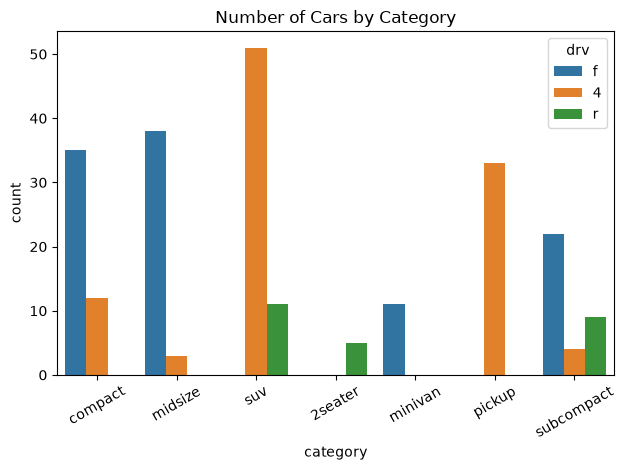

In [15]:
# 종류별 차량 수 막대 그래프
sns.countplot(data=mpg, x='category', hue='drv')

# 제목
plt.title('Number of Cars by Category')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**기대 출력**

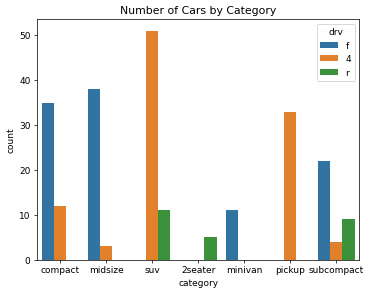


#### 4-3. 구동 방식별 고속도로 연비의 평균을 막대 그래프로 그리고, 같은 값을 `groupby( )` 로도 구하여 출력하시오.

- 제목은 `Mean Highway MPG by Drive Type`
- `groupby( )` 결과의 열 이름은 `mean_hwy`, 소수점 둘째 자리까지 출력

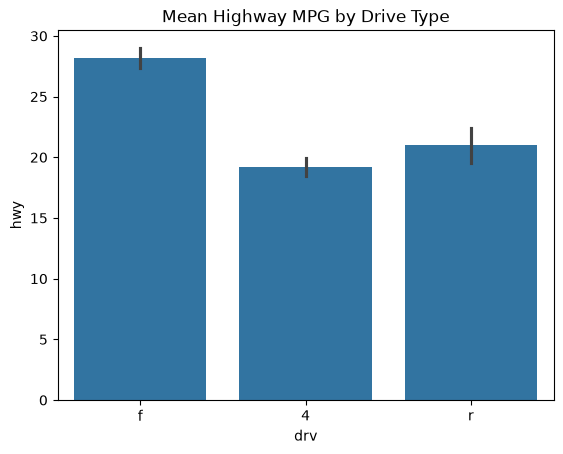

     mean_hwy
drv          
4       19.17
f       28.16
r       21.00


In [17]:
# 구동 방식별 평균 막대 그래프
sns.barplot(data=mpg, x='drv', y='hwy')

# 제목 후 출력
plt.title('Mean Highway MPG by Drive Type')
plt.show()

# groupby 로 같은 값 구하여 출력
print(mpg.groupby('drv').agg(mean_hwy=('hwy', 'mean')).round(2))

**기대 출력**

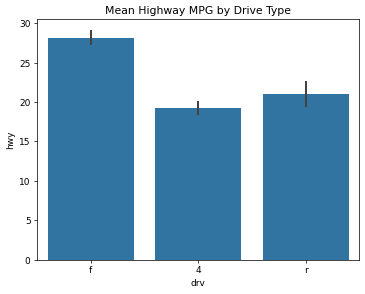

```
     mean_hwy
drv          
4       19.17
f       28.16
r       21.00
```

#### 4-4. 4-1 ~ 4-3 의 결과를 보고 아래 물음에 답하시오.

- 4-2 에서 `pickup`, `minivan`, `2seater` 는 각각 어떤 구동 방식만 있는가?
- 4-3 의 막대 위 검은 세로선 중 **가장 긴 것**은 어느 구동 방식이며, 그 이유는 무엇이라고 생각하는가?

---

##### 답안

- 구동 방식이 하나뿐인 종류: pickup은 사륜(4), minivan은 전륜(f), 2seater는 후륜(r)만 있다.
- 검은 세로선이 가장 긴 구동 방식과 그 이유: 후륜(r)이다. 검은 선은 평균의 신뢰구간을 나타낸다. 후륜 차량은 25대로 사륜(103대), 전륜(106대)보다 표본이 적어 평균 추정의 불확실성이 크다.

---

## 문제 5. 질문에 맞는 그래프 고르기 (제한시간 8분)

- 아래 각 질문에 답하려면 어떤 그래프가 가장 알맞은지 고르고, 그 이유를 한 문장으로 쓰시오
- 선택지: 선 그래프 / 히스토그램 / 상자 그림 / 바이올린 그래프 / `countplot` / `barplot` / 파이 그래프

| 번호 | 질문 | 그래프 | 이유 |
|---|---|---|---|
| 1 | 최근 10년 동안 학과 입학생 수가 어떻게 변했는가? | 선 그래프 | 연도에 따른 입학생 수의 변화 추세를 보여준다. |
| 2 | 이번 시험 점수가 어느 구간에 많이 몰려 있는가? | 히스토그램 | 점수 구간별 학생 수로 분포가 몰린 곳을 확인할 수 있다. |
| 3 | 세 분반의 시험 점수 분포가 서로 다른가? | 상자 그림 | 분반별 중앙값, 퍼짐, 이상치를 나란히 비교할 수 있다. |
| 4 | 학년별로 동아리에 가입한 학생은 몇 명인가? | countplot | 가입 학생 자료에서 학년별 인원수를 세어 비교할 수 있다. |
| 5 | 학과별 평균 취업률을 비교하고 싶다 | barplot | 학과별 취업률의 평균을 막대 높이로 비교할 수 있다. |